# 06 · Embeddings de palabras y traducción secuencia a secuencia

Las imágenes son rejillas de números y las series temporales son listas de números, pero **las palabras son símbolos**. Antes de que una red pueda leer texto, cada palabra tiene que convertirse en un vector, y *qué* vector sea importa muchísimo. Este notebook cubre las dos ideas que llevaron a las redes neuronales de los números al lenguaje:

| Parte | Idea | Experimento |
|---|---|---|
| A · secciones 1-5 | **embeddings de palabras**: el significado como geometría | entrenar embeddings al estilo word2vec desde cero, encontrar analogías como *rey − hombre + mujer ≈ reina* y después medir y eliminar un sesgo de género sembrado en el texto de entrenamiento |
| B · secciones 6-10 | **codificador-decodificador con atención** | traducir de inglés a español con un codificador GRU, un decodificador con atención y búsqueda en haz |

Todo se ejecuta en una CPU en pocos minutos. Ambos corpus se generan en el notebook a partir de pequeñas gramáticas, así que cada resultado es reproducible y no se descarga nada.

Un **embedding** (a veces traducido como "incrustación" o "vector de palabra") es la representación vectorial densa de un símbolo; usamos el término en inglés porque es el que encontrarás en la documentación y en los artículos. Los dos corpus de este notebook están **en inglés**: en la Parte A porque así las analogías se pueden comparar con los resultados clásicos publicados, y en la Parte B porque la tarea consiste precisamente en traducir del inglés al español.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

---
# Parte A · Embeddings de palabras

## 1. De los vectores one-hot a los vectores densos

La codificación más simple le da a cada una de las $V$ palabras su propia posición en un vector de $V$ dimensiones: *cat* = $[0,0,1,0,\dots]$. Esta codificación **one-hot** tiene un defecto fatal: todos los pares de palabras están igual de lejos. *cat* (gato) se parece tanto a *dog* (perro) como a *Tuesday* (martes), así que nada de lo que la red aprende sobre una palabra le sirve para ninguna otra.

Un **embedding** asigna a cada palabra un vector denso y corto (aquí 32 números en lugar de 148), guardado como una fila de una matriz $E \in \mathbb{R}^{V \times d}$. Buscar una palabra es simplemente seleccionar una fila, que es exactamente multiplicar un vector one-hot por $E$. Las filas se aprenden, y la esperanza es que las palabras que se usan de forma parecida acaben cerca unas de otras.

¿Qué significa "que se usan de forma parecida"? La **hipótesis distribucional** (Harris 1954, Firth 1957): *"Conocerás una palabra por las compañías que frecuenta."* *Paris* y *Rome* aparecen junto a las mismas palabras (*capital*, *flew to*, *big city*), así que un modelo que predice las palabras de contexto a partir de una palabra se verá empujado a darles vectores parecidos.

In [2]:
E_toy = torch.randn(5, 3)                       # 5 palabras, embeddings de 3 dimensiones
one_hot = F.one_hot(torch.tensor(2), 5).float()  # la palabra número 2
print("one-hot @ E     :", (one_hot @ E_toy).numpy().round(3))
print("buscar la fila  :", E_toy[2].numpy().round(3), "  (lo mismo, mucho más barato)")

one-hot @ E     : [ 0.403  0.838 -0.719]
buscar la fila  : [ 0.403  0.838 -0.719]   (lo mismo, mucho más barato)


## 2. Un pequeño corpus con estructura oculta

Los embeddings reales se entrenan con miles de millones de palabras. Para ver los mismos efectos en segundos, generamos 60.000 frases a partir de una pequeña gramática con **una estructura que podemos comprobar después**:

* **personas** que se diferencian en tres ejes independientes: género (*man/woman*, *king/queen*), realeza (el *king* vive en un *palace*) y edad (el *boy* va a la *school*);
* **geografía**: países, sus capitales y sus idiomas, conectados por frases coherentes;
* **animales** y **comida**, que aparecen en contextos claramente distintos;
* **profesiones**, donde sembramos deliberadamente un **sesgo**: *engineer, pilot, mechanic, programmer* (ingeniero, piloto, mecánico, programador) aparecen con *he* (él) el 85 % de las veces, y *nurse, receptionist, nanny, secretary* (enfermera, recepcionista, niñera, secretaria) con *she* (ella) el 85 % de las veces. El texto real tiene desviaciones como esta, y la sección 5 muestra lo que les hacen a los embeddings.

In [3]:
people = [  # (masculino, femenino, realeza, joven)
    ("man", "woman", False, False), ("boy", "girl", False, True), ("king", "queen", True, False),
    ("prince", "princess", True, True), ("father", "mother", False, False), ("son", "daughter", False, True),
    ("brother", "sister", False, True), ("uncle", "aunt", False, False), ("husband", "wife", False, False),
]
countries = [("france", "paris", "french"), ("spain", "madrid", "spanish"), ("italy", "rome", "italian"),
             ("germany", "berlin", "german"), ("portugal", "lisbon", "portuguese"), ("japan", "tokyo", "japanese"),
             ("china", "beijing", "chinese"), ("russia", "moscow", "russian"), ("greece", "athens", "greek"),
             ("poland", "warsaw", "polish")]
animals = ["dog", "cat", "horse", "cow", "sheep", "rabbit"]
foods = ["apple", "bread", "cheese", "rice", "soup", "cake"]
jobs_he = ["engineer", "pilot", "mechanic", "programmer"]   # profesiones que el corpus sesgado empareja sobre todo con "he"
jobs_she = ["nurse", "receptionist", "nanny", "secretary"]   # ... y sobre todo con "she"

def sentence(rng):
    r = rng.random()
    if r < 0.40:                                     # personas: género, realeza, edad
        m, f, royal, young = rng.choice(people)
        female = rng.random() < 0.5
        p, pron, poss = (f, "she", "her") if female else (m, "he", "his")
        t = rng.random()
        if t < 0.35:
            return f"the {p} said that {pron} was tired"
        if t < 0.55:
            return f"{pron} is the {p} of the family" if not royal else f"{pron} is the {p} of the kingdom"
        if t < 0.80:
            if royal:
                return rng.choice([f"the {p} lives in the palace", f"the {p} wears a crown", f"the {p} rules the kingdom", f"the {p} sits on the throne"])
            return rng.choice([f"the {p} lives in a house", f"the {p} works in the town", f"the {p} walks to the market"])
        if young:
            return rng.choice([f"the young {p} plays in the garden", f"the {p} goes to school", f"the young {p} learns to read"])
        return rng.choice([f"the old {p} reads {poss} newspaper", f"the {p} drives {poss} car to work", f"the old {p} rests at home"])
    if r < 0.70:                                     # geografía
        c, city, lang = rng.choice(countries)
        return rng.choice([f"{city} is the capital of {c}", f"people in {c} speak {lang}", f"in {city} people speak {lang}",
                           f"we flew to {city} last summer", f"we travelled to {c} last summer", f"{city} is a big city in {c}",
                           f"the {lang} language is spoken in {c}", f"{c} is a country in the world"])
    if r < 0.85:                                     # animales y comida: dos grupos claros
        if rng.random() < 0.5:
            a = rng.choice(animals)
            return rng.choice([f"the {a} eats grass in the field", f"the {a} runs across the farm", f"the farmer feeds the {a}", f"the {a} sleeps in the barn"])
        f_ = rng.choice(foods)
        return rng.choice([f"we eat {f_} for dinner", f"the {f_} is very tasty", f"she bought some {f_} at the market", f"he cooked {f_} in the kitchen"])
    job = rng.choice(jobs_he + jobs_she)             # profesiones, con una desviación de género deliberada
    skew = 0.85 if job in jobs_he else 0.15          # probabilidad de que la frase use "he"
    pron, poss = ("he", "his") if rng.random() < skew else ("she", "her")
    return rng.choice([f"the {job} said that {pron} was tired", f"the {job} finished {poss} work", f"{pron} works as a {job}",
                       f"the {job} drives {poss} car to work"])

rng = random.Random(0)
corpus = [sentence(rng) for _ in range(60000)]
for s in corpus[:8]:
    print(" ", s)

  we eat rice for dinner
  the wife drives her car to work
  the receptionist finished her work
  in lisbon people speak portuguese
  the cheese is very tasty
  the boy works in the town
  the japanese language is spoken in japan
  he is the prince of the kingdom


## 3. Entrenamiento: skip-gram con muestreo negativo

El modelo **skip-gram** (Mikolov et al., 2013, el artículo de "word2vec") convierte la hipótesis distribucional en una tarea de entrenamiento: dada una palabra central, predecir qué palabras aparecen a pocas posiciones de ella.

Predecir la palabra correcta entre todo el vocabulario exige un softmax sobre $V$ palabras, lo que resulta caro con vocabularios grandes. El **muestreo negativo** lo sustituye por una pregunta barata de sí o no: para un par real (central, contexto), empuja la puntuación $\sigma(u_o \cdot v_c)$ hacia 1; para $k$ palabras de "ruido" aleatorias, empuja sus puntuaciones hacia 0.

$$ \mathcal{L} = -\log \sigma(u_o^\top v_c) \;-\; \sum_{j=1}^{k} \log \sigma(-u_{n_j}^\top v_c) $$

Cada palabra tiene dos vectores: $v$ cuando es la palabra central y $u$ cuando es una palabra de contexto. Tras el entrenamiento usamos $v + u$ como embedding de cada palabra (el artículo de GloVe hace lo mismo) y restamos el vector medio del vocabulario. Centrar elimina una dirección que comparten todas las palabras y que, si no, domina las similitudes coseno; prueba los vectores $v$ en bruto en el ejercicio 2 y verás cómo se hunden las analogías de idiomas. Las palabras de ruido se extraen con probabilidad proporcional a $\text{frecuencia}^{0.75}$, lo que muestrea las palabras raras un poco más a menudo que su frecuencia en bruto.

In [4]:
from collections import Counter
counts = Counter(w for s in corpus for w in s.split())
itos = sorted(counts, key=lambda w: -counts[w])
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

window = 3
pairs = []
for s in corpus:
    ids = [stoi[w] for w in s.split()]
    for i, c in enumerate(ids):
        for j in range(max(0, i - window), min(len(ids), i + window + 1)):
            if j != i:
                pairs.append((c, ids[j]))
pairs = torch.tensor(pairs)
freq = torch.tensor([counts[w] for w in itos], dtype=torch.float)
noise_dist = freq ** 0.75 / (freq ** 0.75).sum()
print(f"vocabulario de {V} palabras, {sum(counts.values()):,} tokens, {len(pairs):,} pares (central, contexto)")

class SkipGram(nn.Module):
    def __init__(self, V, d=32):
        super().__init__()
        self.centre = nn.Embedding(V, d)       # v: los embeddings que conservamos
        self.context = nn.Embedding(V, d)      # u: solo se usa durante el entrenamiento
        nn.init.normal_(self.centre.weight, 0, 0.1); nn.init.zeros_(self.context.weight)
    def loss(self, c, o, k=5):
        v = self.centre(c)
        pos = (v * self.context(o)).sum(-1)
        negatives = torch.multinomial(noise_dist, len(c) * k, replacement=True).view(-1, k)
        neg = torch.bmm(self.context(negatives), v.unsqueeze(-1)).squeeze(-1)
        return -(F.logsigmoid(pos) + F.logsigmoid(-neg).sum(-1)).mean()

torch.manual_seed(0)
sg = SkipGram(V)
opt = torch.optim.Adam(sg.parameters(), lr=3e-3)
t0 = time.time()
for epoch in range(3):
    perm = torch.randperm(len(pairs))
    for i in range(0, len(pairs), 2048):
        b = pairs[perm[i:i + 2048]]
        loss = sg.loss(b[:, 0], b[:, 1])
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"época {epoch + 1}: pérdida {loss.item():.3f}  ({time.time() - t0:.0f} s)")
W = sg.centre.weight.detach() + sg.context.weight.detach()
emb = F.normalize(W - W.mean(0), dim=1)    # centrados y de longitud 1: ahora un producto escalar es una similitud coseno

vocabulario de 148 palabras, 374,742 tokens, 1,528,452 pares (central, contexto)


época 1: pérdida 1.590  (6 s)


época 2: pérdida 1.503  (12 s)


época 3: pérdida 1.548  (18 s)


## 4. Explorar el espacio de embeddings

La **similitud coseno** $\cos(a, b) = \frac{a \cdot b}{\|a\|\|b\|}$ mide si dos vectores apuntan en la misma dirección. Nadie le dijo al modelo que *Paris* es una ciudad ni que *dog* es un animal; solo vio qué palabras aparecen junto a cuáles.

In [5]:
def nearest(word, n=5, E=None):
    E = emb if E is None else E
    sims = E @ E[stoi[word]]
    return [(itos[i], round(sims[i].item(), 2)) for i in sims.argsort(descending=True)[1:n + 1]]

for w in ["paris", "spanish", "dog", "cheese", "king", "girl"]:
    print(f"{w:9s} → " + ", ".join(f"{x} ({s})" for x, s in nearest(w)))

paris     → berlin (0.86), beijing (0.85), tokyo (0.83), rome (0.83), warsaw (0.82)
spanish   → greek (0.85), spoken (0.8), portuguese (0.78), french (0.76), speak (0.75)
dog       → cat (1.0), cow (1.0), rabbit (1.0), sheep (0.99), horse (0.99)
cheese    → rice (1.0), bread (0.99), soup (0.99), apple (0.99), cake (0.99)
king      → man (0.79), uncle (0.79), husband (0.78), father (0.78), queen (0.73)
girl      → sister (0.99), daughter (0.99), princess (0.75), young (0.7), boy (0.68)


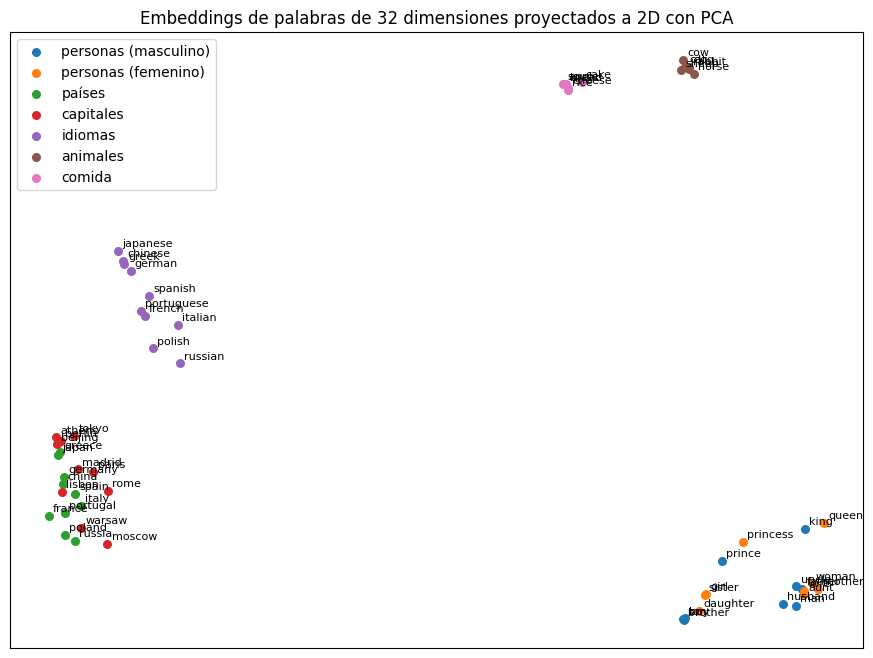

In [6]:
groups = {"personas (masculino)": [p[0] for p in people], "personas (femenino)": [p[1] for p in people],
          "países": [c[0] for c in countries], "capitales": [c[1] for c in countries], "idiomas": [c[2] for c in countries],
          "animales": animals, "comida": foods}
words = [w for ws in groups.values() for w in ws]
X = emb[[stoi[w] for w in words]].numpy()
X = X - X.mean(0)
U, S, Vt = np.linalg.svd(X, full_matrices=False)       # PCA a mano: proyección sobre las 2 direcciones de mayor varianza
P = X @ Vt[:2].T
fig, ax = plt.subplots(figsize=(11, 8))
k = 0
for (name, ws), color in zip(groups.items(), plt.cm.tab10.colors):
    pts = P[k:k + len(ws)]; k += len(ws)
    ax.scatter(pts[:, 0], pts[:, 1], color=color, label=name, s=30)
    for (x, y), w in zip(pts, ws):
        ax.annotate(w, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.legend(); ax.set_title("Embeddings de palabras de 32 dimensiones proyectados a 2D con PCA"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

### Analogías: las relaciones se convierten en direcciones

Si *man → woman* y *king → queen* se diferencian de la misma manera (el género), los vectores diferencia deberían ser aproximadamente iguales, así que

$$ \vec{\text{queen}} \approx \vec{\text{king}} - \vec{\text{man}} + \vec{\text{woman}} $$

Respondemos "*a* es a *b* como *c* es a ?" calculando $\vec b - \vec a + \vec c$ y devolviendo la palabra más parecida que no sea ninguna de las tres de entrada.

In [7]:
def analogy(a, b, c, E=None, among=None):
    # "a es a b como c es a ?"; opcionalmente restringe la respuesta a una lista de palabras candidatas
    E = emb if E is None else E
    q = F.normalize(E[stoi[b]] - E[stoi[a]] + E[stoi[c]], dim=0)
    for i in (E @ q).argsort(descending=True):
        if itos[i] not in (a, b, c) and (among is None or itos[i] in among):
            return itos[i]

for a, b, c in [("man", "woman", "king"), ("king", "queen", "prince"), ("boy", "girl", "brother"),
                ("paris", "france", "rome"), ("france", "french", "japan"), ("berlin", "germany", "madrid")]:
    print(f"{a} : {b}  ::  {c} : {analogy(a, b, c)}")

def score(tests):
    return np.mean([analogy(a, b, c) == d for a, b, c, d in tests])

gender_tests = [(m1, f1, m2, f2) for m1, f1, *_ in people for m2, f2, *_ in people if m1 != m2]
capital_tests = [(ci1, co1, ci2, co2) for co1, ci1, _ in countries for co2, ci2, _ in countries if co1 != co2]
language_tests = [(co1, la1, co2, la2) for co1, _, la1 in countries for co2, _, la2 in countries if co1 != co2]
print()
for name, tests in [("masculino → femenino", gender_tests), ("capital → país", capital_tests), ("país → idioma", language_tests)]:
    print(f"{name:22s} {score(tests):6.1%} de {len(tests)} analogías correctas")

man : woman  ::  king : queen
king : queen  ::  prince : princess
boy : girl  ::  brother : sister
paris : france  ::  rome : italy
france : french  ::  japan : japanese
berlin : germany  ::  madrid : spain

masculino → femenino    38.9% de 72 analogías correctas
capital → país         100.0% de 90 analogías correctas
país → idioma           98.9% de 90 analogías correctas


Las analogías geográficas salen casi perfectas, a partir de nada más que estadísticas de coocurrencia. Las de género son más difíciles, y los fallos son informativos: las personas de este corpus se diferencian en varios ejes a la vez (género, realeza, edad, papel en la familia), así que la respuesta a *son : daughter :: brother : ?* tiene que competir con palabras cercanas que comparten la mayoría de esos ejes. Los embeddings de word2vec reales cometen el mismo tipo de errores.

## 5. Los embeddings heredan los sesgos de su texto

Nuestro corpus dijo *the engineer … he* el 85 % de las veces y *the nurse … she* el 85 % de las veces. El modelo no tiene forma de saber que se trata de un patrón social y no de un hecho sobre la ingeniería, así que lo aprende. Bolukbasi et al. (2016) encontraron lo mismo en embeddings entrenados con artículos de noticias ("el hombre es al programador informático lo que la mujer al ama de casa").

Podemos medirlo: construimos una **dirección de género** $g$ promediando las diferencias de pares claramente marcados por género y proyectamos cada profesión sobre ella. Un valor positivo significa "más cerca de *he*" y uno negativo, "más cerca de *she*".

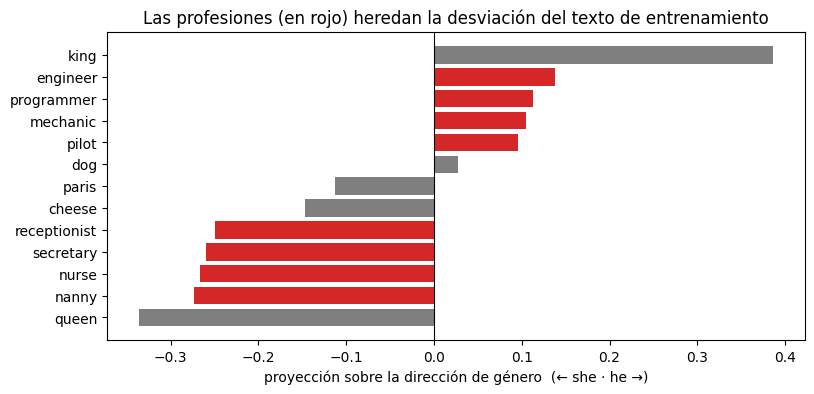

man : engineer :: woman : nanny
he  : pilot    :: she   : nanny

man : <profesión-he> :: woman : ?   (respuesta restringida a profesiones)
  engineer     → nanny
  pilot        → nanny
  mechanic     → nanny
  programmer   → nanny
el 100% de las respuestas son profesiones de 'she'


In [8]:
definitional = [("he", "she"), ("man", "woman"), ("king", "queen"), ("father", "mother"), ("boy", "girl"), ("his", "her")]
g = F.normalize(sum(emb[stoi[m]] - emb[stoi[f]] for m, f in definitional), dim=0)

occupations = jobs_he + jobs_she
proj = {w: (emb[stoi[w]] @ g).item() for w in occupations + ["dog", "cheese", "paris", "king", "queen"]}
fig, ax = plt.subplots(figsize=(9, 4))
order = sorted(proj, key=proj.get)
ax.barh(order, [proj[w] for w in order], color=["#d62728" if w in occupations else "#7f7f7f" for w in order])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("proyección sobre la dirección de género  (← she · he →)")
ax.set_title("Las profesiones (en rojo) heredan la desviación del texto de entrenamiento"); plt.show()

print("man : engineer :: woman :", analogy("man", "engineer", "woman"))
print("he  : pilot    :: she   :", analogy("he", "pilot", "she"))

def bias_probe(E):
    # para cada profesión de "he", ¿a qué profesión la lleva man -> woman?
    flips = [analogy("man", job, "woman", E=E, among=occupations) for job in jobs_he]
    return flips, np.mean([f in jobs_she for f in flips])

flips, rate = bias_probe(emb)
print(f"\nman : <profesión-he> :: woman : ?   (respuesta restringida a profesiones)")
for job, f in zip(jobs_he, flips):
    print(f"  {job:12s} → {f}")
print(f"el {rate:.0%} de las respuestas son profesiones de 'she'")

### Eliminar el sesgo: neutralizar

La solución más simple del mismo artículo es **neutralizar** las palabras que deberían ser neutras en cuanto al género: restarles su componente a lo largo de $g$, de modo que queden exactamente a medio camino entre *he* y *she*:

$$ \vec w_{\text{sin sesgo}} = \vec w - (\vec w \cdot g)\, g $$

Las palabras cuyo género forma parte de su significado (*king*, *mother*) se dejan como están.

In [9]:
emb_db = emb.clone()
for w in occupations:
    v = emb_db[stoi[w]]
    emb_db[stoi[w]] = F.normalize(v - (v @ g) * g, dim=0)

print(f"{'profesión':14s} {'antes':>8s} {'después':>8s}")
for w in occupations:
    print(f"{w:14s} {(emb[stoi[w]] @ g).item():8.3f} {(emb_db[stoi[w]] @ g).item():8.3f}")
flips_db, rate_db = bias_probe(emb_db)
print("\ntras neutralizar, man : <profesión-he> :: woman : ?")
for job, f in zip(jobs_he, flips_db):
    print(f"  {job:12s} → {f}")
print(f"el {rate_db:.0%} de las respuestas son profesiones de 'she' (antes: {rate:.0%})")
print("\npalabras más cercanas a 'nurse' tras neutralizar:", [w for w, _ in nearest("nurse", 4, E=emb_db)])

profesión         antes  después
engineer          0.138   -0.000
pilot             0.095   -0.000
mechanic          0.104    0.000
programmer        0.113   -0.000
nurse            -0.266   -0.000
receptionist     -0.250   -0.000
nanny            -0.273    0.000
secretary        -0.259   -0.000

tras neutralizar, man : <profesión-he> :: woman : ?
  engineer     → pilot
  pilot        → engineer
  mechanic     → pilot
  programmer   → engineer
el 0% de las respuestas son profesiones de 'she' (antes: 100%)

palabras más cercanas a 'nurse' tras neutralizar: ['secretary', 'engineer', 'receptionist', 'programmer']


Las proyecciones son ahora exactamente cero y, en este corpus de juguete, la prueba de analogías ya no asigna profesiones "masculinas" a "femeninas". Los vecinos más cercanos de *nurse* ahora están mezclados, pero su antiguo grupo sigue apareciendo primero: parte del sesgo sobrevive en otras direcciones. En la práctica importan dos advertencias:

* Con embeddings reales, investigaciones posteriores (Gonen y Goldberg, 2019) mostraron que este tipo de proyección sobre todo **oculta** el sesgo en lugar de eliminarlo. El género se aprende a lo largo de muchas direcciones a la vez, así que quitar una de ellas deja las profesiones agrupadas según su antiguo género, y un clasificador normalmente aún puede recuperarlo. El sesgo de un modelo es, en última instancia, una propiedad de sus datos de entrenamiento.
* Los modelos de lenguaje modernos (notebook 08) siguen empezando con una capa de embeddings exactamente como esta, y heredan de la misma forma los patrones de su texto de entrenamiento; por eso evaluar sus sesgos sigue siendo un campo activo.

---
# Parte B · Traducción secuencia a secuencia con atención

## 6. El problema

La traducción transforma una secuencia en otra de **distinta longitud y distinto orden**:

> *the red car* → *el coche rojo* (el adjetivo pasa detrás del sustantivo)
> *he does not eat* → *él no come* (el inglés necesita "does", el español no)

La arquitectura **codificador-decodificador** (encoder-decoder; Sutskever et al., 2014) lo resuelve así:
1. Una RNN **codificadora** lee la frase de origen y la convierte en estados ocultos.
2. Una RNN **decodificadora** genera la frase de destino palabra a palabra, y cada paso depende de la palabra anterior.

La versión original comprimía toda la frase en **un solo** vector, un cuello de botella para las frases largas. La **atención** (Bahdanau et al., 2014) permite que el decodificador mire hacia atrás a *todos* los estados del codificador en cada paso y elija cuáles importan. Esa idea, llevada al extremo, es el transformer (notebook 07).

```
           codificador (GRU bidireccional)                decodificador (GRU + atención)
 the → red → car → <eos>                     <sos> → el → coche → rojo
   h1    h2    h3    h4  ─────── atención ─────►  en cada paso: pesos α sobre h1..h4,
                                                   contexto = Σ α_i h_i, predice la siguiente palabra
```

## 7. Un corpus sintético de inglés → español

Para entrenar en minutos en una CPU, generamos frases a partir de una pequeña gramática: sujeto + (negación) + verbo + artículo + sustantivo + (adjetivo). Aun así contiene las partes difíciles: la conjugación verbal, la concordancia de género (*rojo/roja*, *el/la*), el cambio de orden del adjetivo y el auxiliar inglés "do/does", que desaparece en español.

In [10]:
subjects = [("i", "yo", 0), ("you", "tú", 1), ("he", "él", 2), ("she", "ella", 2), ("we", "nosotros", 3), ("they", "ellos", 4)]
verbs = {  # base en inglés, 3.ª persona en inglés, conjugaciones en español para yo/tú/él/nosotros/ellos
    "eat":  ("eats",  ["como", "comes", "come", "comemos", "comen"]),
    "see":  ("sees",  ["veo", "ves", "ve", "vemos", "ven"]),
    "want": ("wants", ["quiero", "quieres", "quiere", "queremos", "quieren"]),
    "buy":  ("buys",  ["compro", "compras", "compra", "compramos", "compran"]),
    "have": ("has",   ["tengo", "tienes", "tiene", "tenemos", "tienen"]),
    "need": ("needs", ["necesito", "necesitas", "necesita", "necesitamos", "necesitan"]),
}
nouns = [("apple", "manzana", "f"), ("book", "libro", "m"), ("car", "coche", "m"), ("house", "casa", "f"), ("dog", "perro", "m"),
         ("table", "mesa", "f"), ("bread", "pan", "m"), ("letter", "carta", "f"), ("cat", "gato", "m"), ("shirt", "camisa", "f")]
adjectives = [("red", "rojo", "roja"), ("big", "grande", "grande"), ("new", "nuevo", "nueva"),
              ("small", "pequeño", "pequeña"), ("old", "viejo", "vieja"), ("white", "blanco", "blanca"), (None, None, None)]
articles = {"the": {"m": "el", "f": "la"}, "a": {"m": "un", "f": "una"}}

pairs = []
for en_s, es_s, person in subjects:
    third = en_s in ("he", "she")
    for v, (v3, conj) in verbs.items():
        for neg in (False, True):
            for art in articles:
                for en_n, es_n, g in nouns:
                    for en_a, es_am, es_af in adjectives:
                        if neg:
                            en_v = ("does not " if third else "do not ") + v
                            es_v = "no " + conj[person]
                        else:
                            en_v = v3 if third else v
                            es_v = conj[person]
                        first = en_a or en_n
                        en_art = "an" if art == "a" and first[0] in "aeiou" else art
                        en_np = f"{en_art} {en_a + ' ' if en_a else ''}{en_n}"
                        es_np = f"{articles[art][g]} {es_n}" + (f" {es_am if g == 'm' else es_af}" if en_a else "")
                        pairs.append((f"{en_s} {en_v} {en_np}", f"{es_s} {es_v} {es_np}"))

random.seed(0); random.shuffle(pairs)
print(len(pairs), "pares de frases, por ejemplo:")
for p in pairs[:6]:
    print("  EN:", p[0], "\n  ES:", p[1])

10080 pares de frases, por ejemplo:
  EN: you do not eat a small table 
  ES: tú no comes una mesa pequeña
  EN: you do not want an apple 
  ES: tú no quieres una manzana
  EN: she eats an old apple 
  ES: ella come una manzana vieja
  EN: she needs a red cat 
  ES: ella necesita un gato rojo
  EN: he needs a white dog 
  ES: él necesita un perro blanco
  EN: i do not buy a bread 
  ES: yo no compro un pan


In [11]:
class Vocab:
    def __init__(self, sentences):
        self.itos = ["<pad>", "<sos>", "<eos>"] + sorted({w for s in sentences for w in s.split()})
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def encode(self, s):
        return [self.stoi[w] for w in s.split()] + [2]
    def decode(self, ids):
        return " ".join(self.itos[i] for i in ids if i > 2)

src_vocab, tgt_vocab = Vocab([p[0] for p in pairs]), Vocab([p[1] for p in pairs])
PAD, SOS, EOS = 0, 1, 2

def batchify(pp):
    src = [torch.tensor(src_vocab.encode(a)) for a, _ in pp]
    tgt = [torch.tensor(tgt_vocab.encode(b)) for _, b in pp]
    return (nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD),
            nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD))

n_test = 1000
train_pairs, test_pairs = pairs[n_test:], pairs[:n_test]
print(f"vocabulario de origen: {len(src_vocab.itos)} palabras, vocabulario de destino: {len(tgt_vocab.itos)} palabras")
print(f"entrenamiento: {len(train_pairs)} pares, prueba: {len(test_pairs)} pares (frases que el modelo nunca ve)")

vocabulario de origen: 43 palabras, vocabulario de destino: 65 palabras
entrenamiento: 9080 pares, prueba: 1000 pares (frases que el modelo nunca ve)


## 8. El modelo: codificador GRU bidireccional + decodificador con atención

En el paso $t$ del decodificador, con estado oculto $s_{t-1}$, la **atención aditiva (de Bahdanau)** puntúa cada estado del codificador $h_i$, normaliza con softmax y construye un vector de contexto:

$$ e_{t,i} = v^\top \tanh(W_s s_{t-1} + W_h h_i), \qquad \alpha_{t,i} = \text{softmax}_i(e_{t,i}), \qquad c_t = \sum_i \alpha_{t,i} h_i $$

Después, el decodificador consume $[\text{embedding}(y_{t-1}); c_t]$. Tanto el codificador como el decodificador empiezan con una capa `nn.Embedding`: la misma tabla de búsqueda que en la Parte A, pero aquí los vectores se aprenden como subproducto de la traducción en lugar de con un objetivo aparte. Durante el entrenamiento usamos **teacher forcing** (forzado por el profesor): la entrada del decodificador en cada paso es la palabra anterior *real*, no su propia conjetura.

In [12]:
class Encoder(nn.Module):
    def __init__(self, vocab, emb=64, hid=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.rnn = nn.GRU(emb, hid, batch_first=True, bidirectional=True)
        self.bridge = nn.Linear(2 * hid, hid)
    def forward(self, src):
        out, h = self.rnn(self.emb(src))                             # out: (B, S, 2H)
        h0 = torch.tanh(self.bridge(torch.cat([h[0], h[1]], dim=-1)))  # estado inicial del decodificador
        return out, h0

class AdditiveAttention(nn.Module):
    def __init__(self, hid):
        super().__init__()
        self.Ws, self.Wh, self.v = nn.Linear(hid, hid), nn.Linear(2 * hid, hid), nn.Linear(hid, 1, bias=False)
    def forward(self, s, enc_out, mask):
        scores = self.v(torch.tanh(self.Ws(s).unsqueeze(1) + self.Wh(enc_out))).squeeze(-1)   # (B, S)
        scores = scores.masked_fill(~mask, -1e9)                                              # se ignora el relleno
        alpha = scores.softmax(-1)
        return (alpha.unsqueeze(-1) * enc_out).sum(1), alpha

class Decoder(nn.Module):
    def __init__(self, vocab, emb=64, hid=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.att = AdditiveAttention(hid)
        self.rnn = nn.GRUCell(emb + 2 * hid, hid)
        self.out = nn.Linear(hid + 2 * hid + emb, vocab)
    def step(self, y_prev, s, enc_out, mask):
        e = self.emb(y_prev)
        ctx, alpha = self.att(s, enc_out, mask)
        s = self.rnn(torch.cat([e, ctx], -1), s)
        return self.out(torch.cat([s, ctx, e], -1)), s, alpha

class Seq2Seq(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc, self.dec = Encoder(len(src_vocab.itos)), Decoder(len(tgt_vocab.itos))
    def forward(self, src, tgt):                       # teacher forcing (forzado por el profesor)
        enc_out, s = self.enc(src)
        mask = src != PAD
        y_prev = torch.full((src.shape[0],), SOS)
        logits = []
        for t in range(tgt.shape[1]):
            lg, s, _ = self.dec.step(y_prev, s, enc_out, mask)
            logits.append(lg); y_prev = tgt[:, t]
        return torch.stack(logits, 1)
    @torch.no_grad()
    def translate(self, sentence, max_len=12):
        src = torch.tensor([src_vocab.encode(sentence)])
        enc_out, s = self.enc(src)
        y, out, alphas = torch.tensor([SOS]), [], []
        for _ in range(max_len):
            lg, s, a = self.dec.step(y, s, enc_out, src != PAD)
            y = lg.argmax(-1)                          # decodificación voraz
            if y.item() == EOS: break
            out.append(y.item()); alphas.append(a[0])
        return tgt_vocab.decode(out), torch.stack(alphas) if alphas else None

torch.manual_seed(0)
s2s = Seq2Seq()
print(f"parámetros del seq2seq: {count_params(s2s):,}")
print("salida sin entrenar:", s2s.translate("she does not want the red car")[0])

parámetros del seq2seq: 440,321
salida sin entrenar: necesitas no blanco pequeña camisa blanco pequeña camisa blanco pequeña camisa blanco


In [13]:
opt = torch.optim.Adam(s2s.parameters(), lr=2e-3)
t0, losses = time.time(), []
import copy
checkpoints, step = {}, 0
for epoch in range(6):
    random.shuffle(train_pairs)
    for i in range(0, len(train_pairs), 64):
        src, tgt = batchify(train_pairs[i:i + 64])
        logits = s2s(src, tgt)
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(s2s.parameters(), 1.0); opt.step()
        losses.append(loss.item())
        step += 1
        if step in (40, 80):
            checkpoints[step] = copy.deepcopy(s2s.state_dict())   # se guarda para la comparación con búsqueda en haz de la sección 10
    print(f"época {epoch + 1}: pérdida {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

época 1: pérdida 0.0354  (24 s)


época 2: pérdida 0.0016  (47 s)


época 3: pérdida 0.0008  (61 s)


época 4: pérdida 0.0004  (74 s)


época 5: pérdida 0.0003  (87 s)


época 6: pérdida 0.0002  (106 s)


In [14]:
s2s.eval()
exact = sum(s2s.translate(a)[0] == b for a, b in test_pairs)
print(f"exactitud de coincidencia exacta en {len(test_pairs)} frases no vistas: {exact / len(test_pairs):.1%}\n")
for a, b in test_pairs[:6]:
    hyp = s2s.translate(a)[0]
    print(f"EN    : {a}\nES*   : {b}\nSALIDA: {hyp}  {'✓' if hyp == b else '✗'}\n")

exactitud de coincidencia exacta en 1000 frases no vistas: 99.9%

EN    : you do not eat a small table
ES*   : tú no comes una mesa pequeña
SALIDA: tú no comes una mesa pequeña  ✓

EN    : you do not want an apple
ES*   : tú no quieres una manzana
SALIDA: tú no quieres una manzana  ✓

EN    : she eats an old apple
ES*   : ella come una manzana vieja
SALIDA: ella come una manzana vieja  ✓

EN    : she needs a red cat
ES*   : ella necesita un gato rojo
SALIDA: ella necesita un gato rojo  ✓

EN    : he needs a white dog
ES*   : él necesita un perro blanco
SALIDA: él necesita un perro blanco  ✓

EN    : i do not buy a bread
ES*   : yo no compro un pan
SALIDA: yo no compro un pan  ✓



## 9. Visualizar la atención

Cada fila muestra qué palabras en inglés miró el decodificador mientras producía esa palabra en español. Busca:
* el patrón **cruzado** donde el adjetivo cambia de orden (*red car* → *coche rojo*),
* "no" atendiendo a "not", y el verbo conjugado atendiendo al verbo en inglés,
* el pronombre sujeto que a veces atiende a la palabra *contigua* al sujeto en inglés (por ejemplo *ella* → *does*). El codificador es bidireccional, así que cada $h_i$ ya mezcla información de sus vecinas (*does* solo aparece después de *he/she*). Los pesos de atención son una pista útil sobre lo que usa el modelo, no una alineación exacta de palabras.

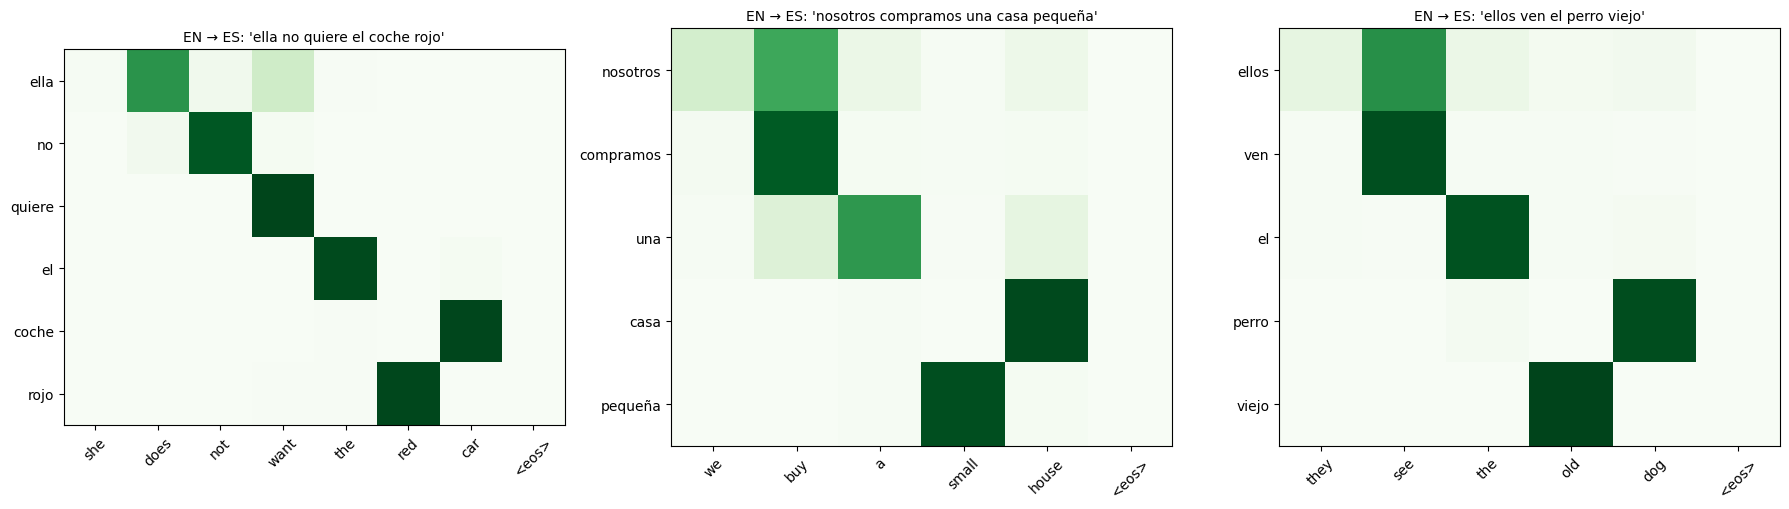

In [15]:
examples = ["she does not want the red car", "we buy a small house", "they see the old dog"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, sent in zip(axes, examples):
    out, alpha = s2s.translate(sent)
    ax.imshow(alpha.numpy(), cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(len(sent.split()) + 1)); ax.set_xticklabels(sent.split() + ["<eos>"], rotation=45)
    ax.set_yticks(range(len(out.split()))); ax.set_yticklabels(out.split())
    ax.set_title(f"EN → ES: '{out}'", fontsize=10)
plt.tight_layout(); plt.show()

## 10. Búsqueda en haz: buscar una frase mejor

`translate` usa **decodificación voraz** (greedy): en cada paso se compromete con la palabra más probable. Eso no es lo mismo que encontrar la *frase* más probable: una palabra que parece la mejor ahora puede obligar a una continuación mala después.

La **búsqueda en haz** (beam search) conserva las $B$ traducciones parciales más probables en cada paso. Cada una se amplía con todas las posibles palabras siguientes, y solo sobreviven las $B$ mejores de todos esos candidatos. Las puntuaciones son sumas de logaritmos de probabilidad, divididas por la longitud para no penalizar injustamente las salidas más largas. Con $B = 1$ se reduce a la decodificación voraz.

El efecto se ve mejor en un modelo que todavía duda, así que comparamos ambos decodificadores con puntos de control guardados al principio de la primera época, además de con el modelo final.

In [16]:
@torch.no_grad()
def beam_translate(model, sentence, beam=4, max_len=12):
    src = torch.tensor([src_vocab.encode(sentence)])
    enc_out, s0 = model.enc(src)
    mask = src != PAD
    beams = [(0.0, [SOS], s0)]                   # (suma de log-probabilidades, tokens, estado del decodificador)
    finished = []
    for _ in range(max_len):
        candidates = []
        for score, toks, s in beams:
            lg, s_new, _ = model.dec.step(torch.tensor([toks[-1]]), s, enc_out, mask)
            logp = lg.log_softmax(-1)[0]
            top = logp.topk(beam)
            for lp, idx in zip(top.values.tolist(), top.indices.tolist()):
                candidates.append((score + lp, toks + [idx], s_new))
        candidates.sort(key=lambda c: c[0] / (len(c[1]) - 1), reverse=True)
        beams = []
        for c in candidates:
            (finished if c[1][-1] == EOS else beams).append(c)
            if len(beams) == beam:
                break
        if not beams or len(finished) >= beam:
            break
    best = max(finished + beams, key=lambda c: c[0] / (len(c[1]) - 1))
    return tgt_vocab.decode(best[1][1:])

snapshots = {}
for k, state in checkpoints.items():
    snapshots[f"tras {k} lotes"] = Seq2Seq(); snapshots[f"tras {k} lotes"].load_state_dict(state); snapshots[f"tras {k} lotes"].eval()
snapshots["entrenado del todo"] = s2s
early = snapshots["tras 40 lotes"]
print(f"{'modelo':22s} {'voraz':>8s} {'haz=4':>8s}   (coincidencia exacta en {len(test_pairs)} frases no vistas)")
for name, m in snapshots.items():
    g = np.mean([m.translate(a)[0] == b for a, b in test_pairs])
    bs = np.mean([beam_translate(m, a) == b for a, b in test_pairs])
    print(f"{name:22s} {g:8.1%} {bs:8.1%}")

fixed, broken = [], []
for a, b in test_pairs:
    gr, bm = early.translate(a)[0], beam_translate(early, a)
    if gr != b and bm == b: fixed.append((a, gr, bm))
    if gr == b and bm != b: broken.append((a, gr, bm))
print(f"\ntras 40 lotes: la búsqueda en haz arregla {len(fixed)} frases y estropea {len(broken)}")
for title, rows in [("arreglada por la búsqueda en haz", fixed[:2]), ("estropeada por la búsqueda en haz", broken[:2])]:
    for a, gr, bm in rows:
        print(f"\n[{title}]\nEN    : {a}\nvoraz : {gr}\nhaz   : {bm}")

modelo                    voraz    haz=4   (coincidencia exacta en 1000 frases no vistas)


tras 40 lotes             55.8%    54.2%


tras 80 lotes             94.8%    94.4%


entrenado del todo        99.9%   100.0%



tras 40 lotes: la búsqueda en haz arregla 25 frases y estropea 41

[arreglada por la búsqueda en haz]
EN    : she eats an old apple
voraz : ella no come una manzana vieja
haz   : ella come una manzana vieja

[arreglada por la búsqueda en haz]
EN    : she has a big letter
voraz : ella come una carta grande
haz   : ella tiene una carta grande

[estropeada por la búsqueda en haz]
EN    : she wants the big cat
voraz : ella quiere el gato grande
haz   : ella come el gato grande

[estropeada por la búsqueda en haz]
EN    : i have the small dog
voraz : yo tengo el perro pequeño
haz   : yo veo el perro pequeño


El resultado es instructivo: con el modelo poco entrenado, la búsqueda en haz arregla algunas frases pero estropea todavía más, así que la exactitud global *baja* ligeramente. La búsqueda en haz solo puede encontrar traducciones que el modelo ya puntúa alto. Ayuda cuando el error es un *compromiso prematuro* (la frase correcta tenía una puntuación total mayor que la voraz), y no puede ayudar, o incluso perjudica, cuando las propias probabilidades del modelo están mal, como ocurre al principio del entrenamiento. En los sistemas de traducción reales, donde los modelos son buenos pero no seguros, la búsqueda en haz suele dar una mejora modesta y constante, a cambio de $B$ veces más cálculo por frase. Es lo habitual en traducción y reconocimiento de voz; los modelos de chat suelen *muestrear* en su lugar (notebook 08), porque en el texto abierto la frase más probable tiende a ser sosa y repetitiva.

## Resumen

| Idea | Qué hace | Dónde sigue viva |
|---|---|---|
| embeddings de palabras | las palabras se convierten en vectores; uso parecido → vectores cercanos; relaciones → direcciones | la primera capa de todo modelo de lenguaje |
| sesgo en los embeddings | los patrones estadísticos del texto se convierten en geometría, incluidos los indeseados | la evaluación de sesgos de los LLM modernos |
| codificador-decodificador | leer una entrada completa y después generar una salida de otra longitud | traducción, resumen, reconocimiento de voz |
| atención | en cada paso de salida, mirar atrás a cada posición de entrada y elegir lo que importa | **el transformer** (notebook 07) |
| búsqueda en haz | buscar una *frase* probable, no una sucesión de palabras probables | decodificadores de traducción y de voz |

Los pesos de atención que dibujaste en la sección 9 son la semilla del transformer. El notebook 07 elimina por completo la recurrencia y construye una red **solo** con atención y MLP de propagación hacia adelante.

## Ejercicios

1. **Embeddings:** cambia el tamaño del embedding a 8 y a 128. ¿Cómo cambian las puntuaciones de las analogías? ¿Y el tamaño de la ventana (1 frente a 5)?
2. **Embeddings:** usa solo los vectores centrales, sin centrar (`emb = F.normalize(sg.centre.weight.detach(), dim=1)`). ¿Qué familia de analogías se rompe, y por qué una dirección compartida podría perjudicarla más?
3. **Embeddings:** elimina la desviación (usa 0.5 para todas las profesiones en `sentence`) y vuelve a entrenar. ¿Qué le pasa a la gráfica del sesgo?
4. **Embeddings:** después de neutralizar, imprime `nearest("nurse", E=emb_db)`. ¿Qué palabras siguen más cerca y qué dice eso del método?
5. **Seq2seq:** quita la atención (usa solo el estado final del codificador como contexto). ¿Cuánto baja la exactitud, y recupera algo la búsqueda en haz?
6. **Seq2seq:** deja fuera del entrenamiento todas las frases que contengan *"white cat"*. ¿Puede el modelo traducir *"the white cat"* correctamente (generalización composicional)?